# 01 · Data Cleaning & KPIs

**Goal:** load the raw Superstore data, clean it, and calculate the key business metrics.

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path("../data")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Load the data

Load the raw Superstore CSV (`data/raw/Sample - Superstore.csv`). The file isn't UTF-8, so it's read with `latin-1` encoding.

In [66]:
df = pd.read_csv(DATA_DIR / "raw" / "Sample - Superstore.csv", encoding="latin-1")

## 2. First look

Shape, column names, data types and the first few rows.

In [67]:
print(df.head())
print(df.info())

   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City       State  \
0      Claire Gute   Consumer  United States        Henderson    Kentucky   
1      Claire Gute   Consumer  United States        Henderson    Kentucky   
2  Darrin Van Huff  Corporate  United States      Los Angeles  California   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale     Florida   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale     Florida   

   Postal Code Region       Product ID         Cat

## 3. Data quality checks

Checked for missing values and duplicate rows.

**Result:** no missing values and no duplicate rows. Discounts range from 0% to 80%, and some order lines have large losses (lowest profit: −$6,600), which the discount chart below looks into.

In [68]:
print(df.isna().sum())
print(df.duplicated().sum())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64
0


## 4. Clean & add columns

- Convert `Order Date` and `Ship Date` to datetime (`pd.to_datetime`)
- Add: `Order Year`, `Order Month`, `Ship Days` (ship date − order date), `Profit Margin` (profit ÷ sales)

In [69]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Order Day"] = df["Order Date"].dt.day

df["Ship Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

df["Profit Margin"] = df["Profit"] / df["Sales"]

df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Day,Ship Days,Profit Margin
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,8,3,0.1600
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,8,3,0.3000
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,12,4,0.4700
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,11,7,-0.4000
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,11,7,0.1125


## 5. KPIs

- Total sales
- Total profit
- Profit margin (%)
- Number of orders
- Average order value

One order can span several rows (one per product), so orders are counted with unique `Order ID`s.

In [70]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
profit_margin = total_profit / total_sales * 100
num_orders = df["Order ID"].nunique()
avg_order_value = total_sales / num_orders

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Number of Orders: {num_orders}")
print(f"Average Order Value: ${avg_order_value:,.2f}")


Total Sales: $2,297,200.86
Total Profit: $286,397.02
Profit Margin: 12.47%
Number of Orders: 5009
Average Order Value: $458.61


## 6. Breakdowns

- Sales & profit by **Category** and **Sub-Category**
- Sales & profit by **Region** and **Segment**
- Top 10 products by sales vs. top 10 by profit

In [71]:
df.groupby(["Category", "Sub-Category"])[["Sales", "Profit"]].sum().sort_values("Profit", ascending=False)
df.groupby("Region")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
df.groupby("Segment")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)

products = df.groupby("Product Name")[["Sales", "Profit"]].sum()
products.nlargest(10, "Sales")
products.nlargest(10, "Profit")

,Sales,Profit
Product Name,,
Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7753.0390
Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836
Canon PC1060 Personal Laser Copier,11619.834,4570.9347
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4094.9766
Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.290,3696.2820
Ibico EPK-21 Electric Binding System,15875.916,3345.2823


## 7. Charts

- Monthly sales trend (line chart)
- Sales and profit by category (bar chart)
- Discount vs. profit (scatter plot)

Charts are saved to `reports/figures/`.

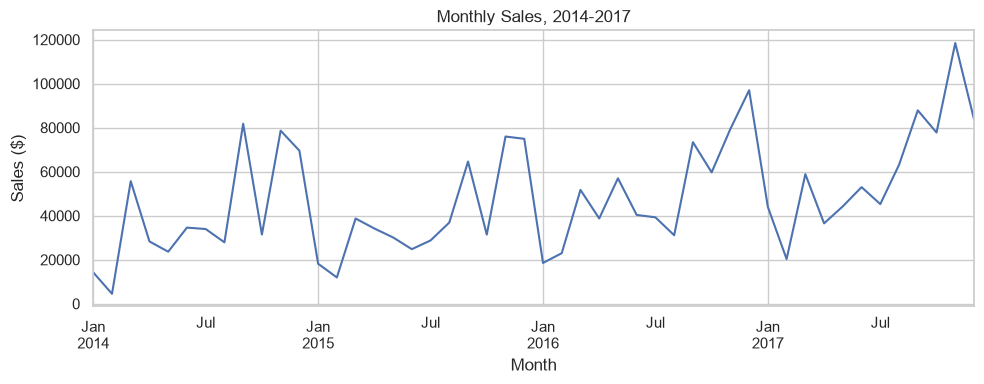

In [72]:
monthly = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()

monthly.plot(figsize=(10, 4))
plt.title("Monthly Sales, 2014-2017")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.savefig("../reports/figures/monthly_sales.png", dpi=150)
plt.show()

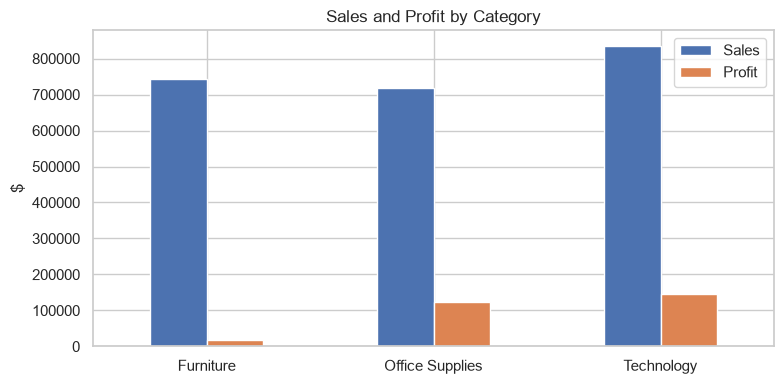

In [73]:
by_category = df.groupby("Category")[["Sales", "Profit"]].sum()

by_category.plot(kind="bar", figsize=(8, 4))
plt.title("Sales and Profit by Category")
plt.xlabel("")
plt.ylabel("$")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../reports/figures/sales_profit_by_category.png", dpi=150)
plt.show()

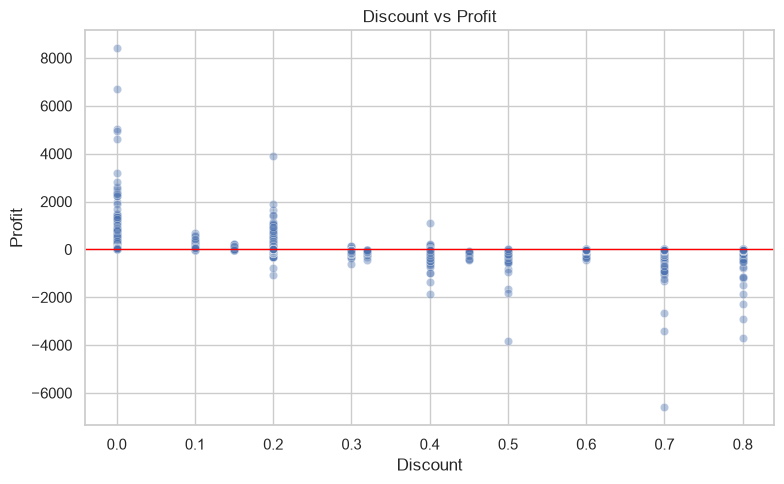

In [74]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.4)
plt.axhline(0, color="red", linewidth=1)
plt.title("Discount vs Profit")
plt.tight_layout()
plt.savefig("../reports/figures/discount_vs_profit.png", dpi=150)
plt.show()

## 8. Save the cleaned data

Saved to `data/processed/superstore_clean.csv` for notebook 02 and the dashboard.

In [75]:
df.to_csv(DATA_DIR / "processed" / "superstore_clean.csv", index=False)

## Takeaways

- **$2.3M in sales and $286k in profit (12.5% margin)** across 5,009 orders, with an average order value of $459.
- **Technology is the most profitable category** (17.4% margin). **Furniture barely breaks even**: $742k in sales but only $18k profit (2.5% margin), dragged down by Tables (−$17.7k) and Bookcases (−$3.5k).
- **Sales grew 51% from 2014 to 2017** with a clear seasonal pattern: September, November and December are the busiest months every year, and January and February the slowest.
- **Heavy discounts wipe out profit.** 97% of order lines discounted 30% or more lost money (−$135k combined), compared with 6% of lines discounted 20% or less.
- **West is the strongest region** (14.9% margin); **Central has the weakest margin** (7.9%) despite being third in sales.